Billy York

07/06/26

# Choosing and Building the Model

## Introduction

This milestone introduces the concept of model pipelines and serializing / pickling them to disk for easier deployment. First was picking a model, then feature engineering, creating the pipeline, and saving to disk. The final model was selected based on its R2 Score, Mean Absolute Percent Error, Root-Mean-Squared Error, and Training and Inference Time.

## Model Selection
Five models were tested for regression on the house price dataset. In order from least performant to most, Linear Regression, SGD Regression, MLP Regression, Histogram Gradient Boosting Regression, and Random Forest Regression. 

### Base Model Comparison Table

| Model                                  | R2 Score           | RMSE               | MAPE                | Time                 |
| -------------------------------------- | ------------------ | ------------------ | ------------------- | -------------------- |
| Linear Regression                      | 0.7178824494548395 | 182320.0989900138  | 0.24499585669647914 | 0.24333887500688434s |
| SGD Regressor                          | 0.7175064550955961 | 182441.55280118788 | 0.2452343871242329  | 1.253164374968037s   |
| MLP Regressor                          | 0.9115637719187181 | 102078.57559593947 | 0.13494659371602555 | 45.62557299993932s   |
| Histogram Gradient Boosting Regression | 0.9397700085597176 | 84241.4622113472   | 0.12068330954941732 | 2.8492689579725266s  |
| Base Random Forest Regressor           | 0.9932239599404794 | 28255.791559672296 | 0.03523341349640544 | 49.60990266595036s   |

### Base Model R2 Score Chart (Higher is Better)

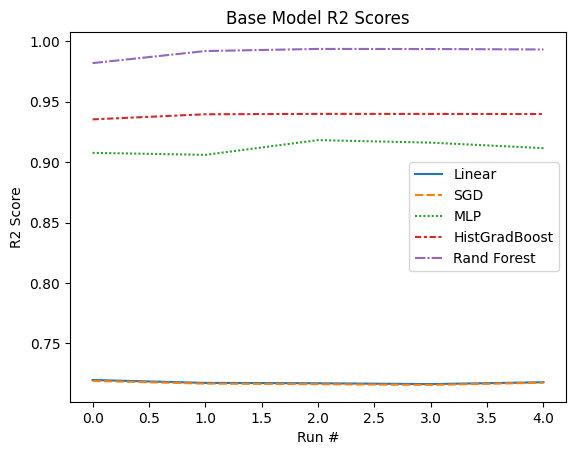

There is a clear hierarchy with the Random Forest regression at the top, followed by the Histogram Gradient Boosting regression, then the Multi-Layered Perceptron, and SGD Regression and Linear Regression at the bottom. A base R2 Score of 0.99+ implies one of two things have occurred. Either the model has gotten incredibly lucky and there is a very strong correlation in the data to the price, or there is overfitting from the repeated records in the dataset making it possible for the test data to also be in training data. With how flat the scores are across 5 training runs, each with increasing amounts of data, it is more likely overfitting is occurring. 

### Base Model MAPE Chart (Lower is Better)

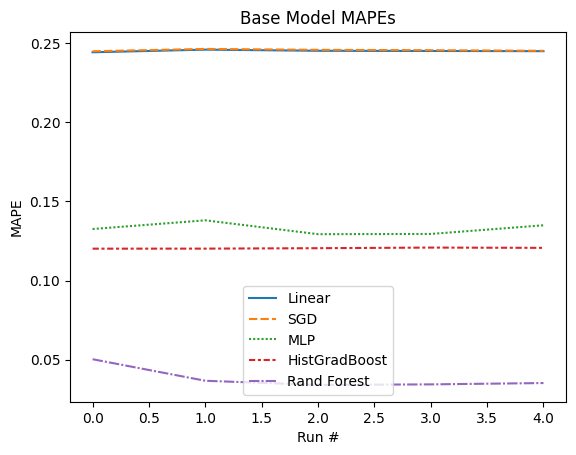

A similar hierarchy to the R2 scores appears in the MAPE with Random Forest again being the best with a MAPE of 0.03, meaning its price predictions would have a tolerance of about +/- 3%. This has similar implactions to the R2 scores with a possibility of overfitting. There is some improvement in MAPE in the Random Forest from the first run to the second, but as it is flat for the remainder of the runs and the other models are mostly flat for all of their runs, there is similar evidence for overfitting.

### Base Model RMSE Chart (Lower is Better)

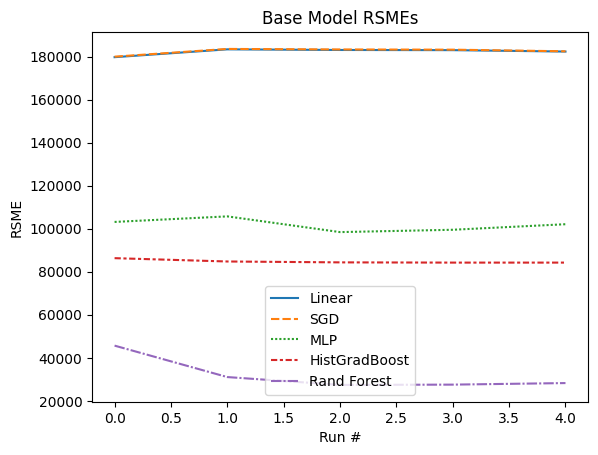

The RMSE chart is almost identical to the MAPE chart with the same dip from run 1 to 2 in the Random Forest. Working on the assumption these results are usable, it would mean the Random Forest's price predictions should be within +/- about $28000 from the true price.

### Base Model Time Chart (Lower is Better)

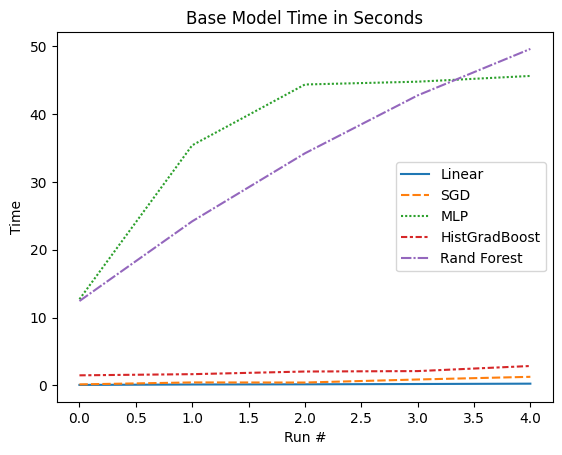

The heirarchy is inverted somewhat with the Linear, SGD, and Histogram Gradiet Boosting Regressions having the lowest times by a significant margin. Random Forest scales linearly with the dataset and the MLP regression appears to scale logarithmically, creating an intersection between the two where MLP takes less time by run 4.

### Base Model Evaluation

Random Forest is the clear winner in 3 of the 4 metrics. If training time also needed to be significantly lower without sacrificing too much accuracy, then the Histogram Gradient Boosting Regression would be a serious contender, but the difference of more than 50,000 in the RMSE shows clearly how sigificant the accuracy sacrifice could be. The MLP could be given more epochs as it warned that it had not converged, so it is possible it could out perform the Random Forest, but it would sacrifice significant time with no guarantee of improvement. 

## Feature Engineering

Random Forest was the most performant so it was selected for use in the feature engineering section. 5 features were engineered with minimal performance over the base Random Forest. The first test is converting latitude and longitude to polar coordinates after transforming them to be centered around the geographic center of Seattle found [here](https://www.seattletimes.com/pacific-nw-magazine/the-center-of-seattle/). The second takes advantage of the 15 nearest neighbors lot and living size data to effectively scale those features based on the record's own lot and living sizes. The next one is kind of an imputation to modify the renovation records so if any are 0, they instead become the year the house was built. Condition, Grade, Floors, Bedrooms, Bathrooms, and View are all One Hot Encoded. Lastly, since the total schools is likely colinear the number of other schools, it's instead used as the divisor for the population to get a ratio of population to schools. Then all the engineered features are combined into a single model to test its performance. As seen below, there was marginal to no improvement over the base model from any given feature or the combination of them. With the evidence of overfitting occurring, a second test is likely necessary once new data is introduced. 

### Feature Engineering Comparison Table

| Model                                      | R2 Score           | RMSE               | MAPE                 | Time                |
| ------------------------------------------ | ------------------ | ------------------ | -------------------- | ------------------- |
| Polar Random Forest Regressor              | 0.9932229207537446 | 28257.958158290803 | 0.03524034992666966  | 52.33469199994579s  |
| Relative Random Forest Regressor           | 0.9932219145187585 | 28260.055897577273 | 0.035232032949664344 | 49.82693520793691s  |
| Reno Random Forest Regressor               | 0.9932247179913062 | 28254.21099602044  | 0.03523446776649429  | 54.72853858303279s  |
| One Hot Random Forest Regressor            | 0.993222717624366  | 28258.381642970904 | 0.03524369758343681  | 61.75838241702877s  |
| Population:Schools Random Forest Regressor | 0.9932239666178526 | 28255.77763749133  | 0.03523109104761942  | 48.565552374813706s |
| Combined Random Forest Regressor           | 0.9932216328884274 | 28260.642995973343 | 0.03523292655581062  | 69.59107624995522s  |

### Feature Engineering R2 Score Chart (Higher is Better)

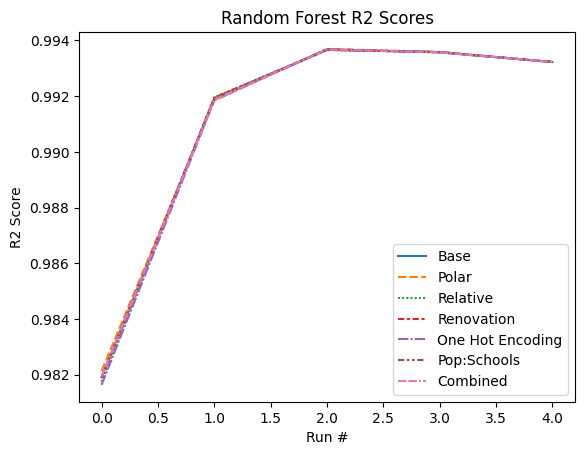

There is basically no change in the R2 score from feature engineering. Looking back at the table, R2 doesn't change until the 6th significant digit. 

### Feature Engineering MAPE Chart (Lower is Better)

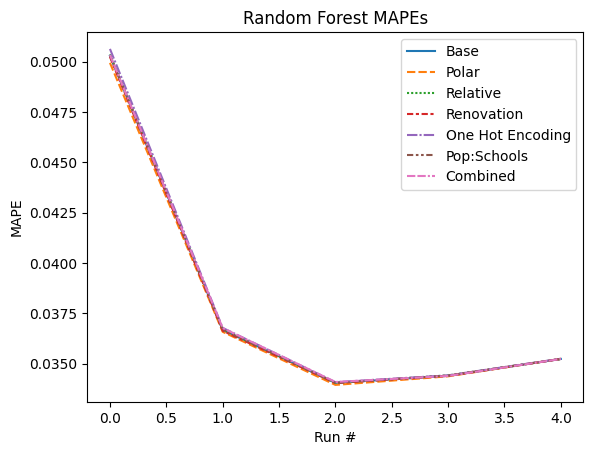

The MAPEs tell a similar story to R2, changing on the 4th significant digit.

### Feature Engineering RMSE Chart (Lower is Better)

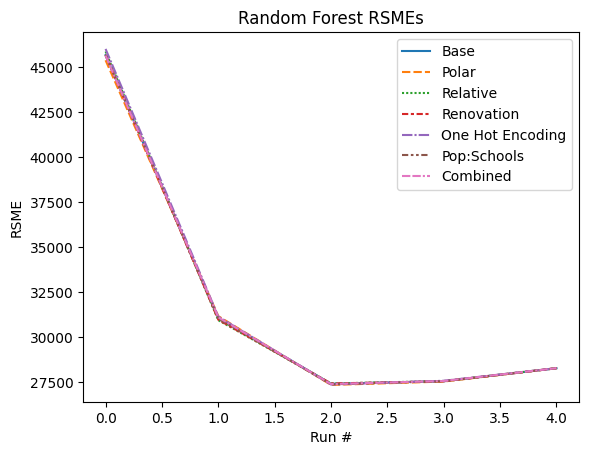

The RMSEs again look almost identical to the MAPEs, similarly being the same until the 4th significant digit.

### Feature Engineering Time Chart (Lower is Better)

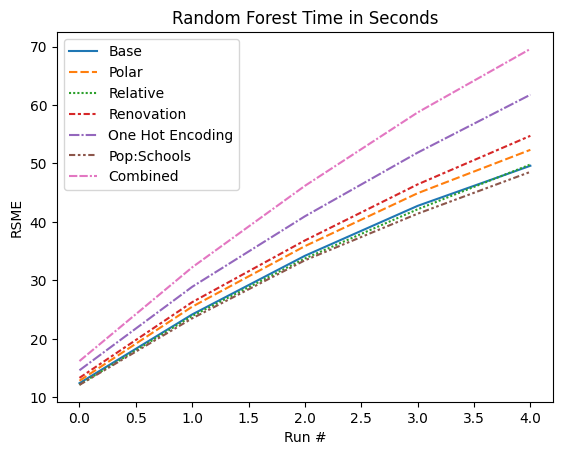

The timing shows what is expected, the feature engineering that increase the number of features take longer to train. 

### Evaluation

There are marginal improvements from feature engineering and notably from some light experimentation, there is not a linear relationship between the performance of the engineered feature alone and combined with another engineered feature. Because there is likely overfitting and therefore difficult to determine which engineered features improve the performance of the model, the final model will simply use all of them and can be further tuned after new data is introduced.

## Pipeline Serialization

![milestone4.png](milestone4.png)

The pipeline primarily uses Function Transformers for the engineered features, including the one-hot-encoding, due to the library's version's need to be last in the pipeline based on its return value. Since all of the Function Transformers reference more than one column or return more than one column, they could not be ColumnTransformers, requiring the entire DataFrame to be their inputs. The long number of steps and large inputs leads to having a large final pipeline file of about 300MB. This can be tuned further later, but for now will require GitHub's use of `git-lfs` to store in the repository. 

In [ ]:
from time import perf_counter

import dill as pickle
import pandas as pd
import psycopg
import seaborn as sns
from IPython.display import Markdown, display
from psycopg.rows import dict_row
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import (
    mean_absolute_percentage_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


In [2]:
user = 'postgres'
password = 'psql-password'
host = '127.0.0.1'

In [ ]:
conn_string = f'postgresql://{user}:{password}@{host}:5432/house_price_prediction_service'
with psycopg.connect(conn_string, row_factory=dict_row) as conn:
    with conn.cursor() as cur:
        cur.execute('SELECT * FROM cleaned_home_sale_events WHERE economic_conditions = 1.0 ORDER BY event_timestamp ASC;')
        rows = cur.fetchall()

In [4]:
df = pd.DataFrame.from_records(rows)
df = df.drop(labels=['id', 'event_timestamp'], axis=1)
df = df.astype({'economic_conditions': 'float64', 'price': 'float64', 'lat': 'float64', 'long': 'float64'})
df.head()

,lat,long,zipcode,sqft_lot,sqft_living,sqft_above,sqft_basement,has_basement,sqft_lot15,sqft_living15,...,waterfront,price,economic_conditions,zipcode_population,zipcode_public_high_schools,zipcode_public_middle_schools,zipcode_public_primary_schools,zipcode_public_other_schools,zipcode_public_unknown_schools,zipcode_public_total_schools
0,47.6950,-122.399,98117,12100,3080,2080,1000,True,6581,2100,...,0,674955.380204,1.0,94095,1,1,5,1,0,8
1,47.7426,-122.288,98155,15435,2240,1390,850,True,10750,2240,...,0,448457.514031,1.0,98334,1,1,4,3,0,9
2,47.7293,-122.284,98125,11583,2780,1190,1590,True,10241,2580,...,0,632136.452648,1.0,111243,2,0,5,0,0,7
3,47.5875,-122.240,98040,8250,2540,1440,1100,True,11000,2540,...,0,770841.475428,1.0,68097,1,1,3,0,0,5
4,47.5537,-121.996,98029,5809,2980,2980,0,False,3416,2120,...,0,800763.844605,1.0,73044,0,2,3,0,1,6


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 171764 entries, 0 to 171763
Data columns (total 29 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   lat                             171764 non-null  float64
 1   long                            171764 non-null  float64
 2   zipcode                         171764 non-null  int64  
 3   sqft_lot                        171764 non-null  int64  
 4   sqft_living                     171764 non-null  int64  
 5   sqft_above                      171764 non-null  int64  
 6   sqft_basement                   171764 non-null  int64  
 7   has_basement                    171764 non-null  bool   
 8   sqft_lot15                      171764 non-null  int64  
 9   sqft_living15                   171764 non-null  int64  
 10  yr_built                        171764 non-null  int64  
 11  yr_renovated                    171764 non-null  int64  
 12  was_renovated              

In [ ]:
def make_polar(old_df, y=None):
    # Coords from https://www.seattletimes.com/pacific-nw-magazine/the-center-of-seattle/
    from numpy import atan2, sqrt
    center_lat = 47.62101388888889
    center_long = -122.33328888888889
    df = old_df.copy()
    df['lat'] = df['lat'] - center_lat
    df['long'] = df['long'] - center_long
    df['radius'] = sqrt((df['lat'] ** 2) + (df['long'] ** 2))
    df['theta'] = atan2(df['long'], df['lat'])
    df = df.drop(labels=['lat', 'long'], axis=1)
    return df

def make_relative_to_NN(old_df, y=None):
    df = old_df.copy()
    df['relative_lot'] = df['sqft_lot'] - df['sqft_lot15']
    df['relative_living'] = df['sqft_living'] - df['sqft_living15']
    df = df.drop(labels=['sqft_lot15', 'sqft_living15'], axis=1)
    return df

def combine_build_reno(old_df, y=None):
    from datetime import datetime
    df = old_df.copy()
    df['yrs_since_last_construction'] = datetime.now().year - df[['yr_built', 'yr_renovated']].values.max(1)
    # df = df.drop(labels='yr_renovated', axis=1)
    df['yr_renovated'] = df[['yr_built', 'yr_renovated']].values.max(1)
    return df

def one_hot_encode(old_df, y=None):
    from pandas import CategoricalDtype, get_dummies
    df = old_df.copy()
    if 'has_basement' not in df.columns:
        df['has_basement'] = df['sqft_basement'] > 0
    if 'was_renovated' not in df.columns:
        df['was_renovated'] = df['yr_built'] < df['yr_renovated']
    cols_to_encode = {
        'condition': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
        'grade': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
        'floors': [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0],
        'bedrooms': [0, 1, 2, 3, 4, 5, 6],
        'bathrooms': [0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 2.75, 3.0, 3.25, 3.5, 3.75, 4.0, 4.25, 4.5, 4.75, 5.0, 5.25, 5.5, 5.75, 6.0],
        'view': [0, 1, 2, 3, 4]}
    
    for col in cols_to_encode.keys():
        df = df.drop(labels=col, axis=1).join(get_dummies(df[col].astype(CategoricalDtype(categories=cols_to_encode[col])), prefix=col))
    return df

def pop_school_ratio(old_df, y=None):
    df = old_df.copy()
    df['pop_school_ratio'] = df['zipcode_population'] / df['zipcode_public_total_schools']
    df = df.drop(labels=['zipcode_population', 'zipcode_public_total_schools'], axis=1)
    return df

def debug(old_df, y=None):
    print('Made it!')
    print(type(old_df))
    return old_df

In [ ]:
class PricePipeline:
    def __init__(self, df, n_splits=5, regressor=None, regressor_name='None', engineered_features=[]):
        self.df = df
        self.tss = TimeSeriesSplit(n_splits=n_splits)
        self.regressor = regressor
        self.regressor_name = regressor_name
        self.r2_scores = []
        self.mapes = []
        self.rmses = []
        self.times = []
        self.engineered_transformers = {
            'polar': FunctionTransformer(make_polar),
            'relative': FunctionTransformer(make_relative_to_NN),
            'reno': FunctionTransformer(combine_build_reno),
            'pop': FunctionTransformer(pop_school_ratio),
            # 'ohe': ColumnTransformer(remainder='passthrough', transformers=[('encoder', OneHotEncoder(sparse_output=False), ['condition', 'grade', 'floors', 'bedrooms', 'bathrooms', 'view'])]),
            'ohe': FunctionTransformer(one_hot_encode),
            'debug': FunctionTransformer(debug)
        }
        self.transformers = []
        for i in range(len(engineered_features)):
            self.transformers.append((f'engineered_features[i]{i}', self.engineered_transformers[engineered_features[i]]))
        self.transformers.append(('impute', ColumnTransformer(remainder='passthrough', transformers=[('imputer', SimpleImputer(), ['zipcode', 'sqft_living', 'sqft_above'])])))
        self.transformers.append(('scale', StandardScaler()))
        self.transformers.append(('predict', regressor))
        self.pipeline = Pipeline(self.transformers)

    def train(self):
        for i, (train_idx, test_idx) in enumerate(self.tss.split(self.df)):
            train_df = self.df.iloc[train_idx]
            test_df = self.df.iloc[test_idx]
            train_y = train_df['price']
            test_y = test_df['price']
            train_X = train_df.drop(labels='price', axis=1)
            test_X = test_df.drop(labels='price', axis=1)
            
            start = perf_counter()
            self.pipeline.fit(train_X, train_y)
            y_pred = self.pipeline.predict(test_X)
            end = perf_counter()
            
            self.r2_scores.append(r2_score(test_y, y_pred))
            self.mapes.append(mean_absolute_percentage_error(test_y, y_pred))
            self.rmses.append(root_mean_squared_error(test_y, y_pred))
            self.times.append(end - start)

    def get_pipeline(self):
        return self.pipeline

    def get_stats(self):
        return (self.r2_scores, self.mapes, self.rmses, self.times)

    def get_table(self):
        table  = f'| {self.regressor_name} Run # | R2 Score | RMSE | MAPE | Time |\n'
        table +=  '| --------------------------- | -------- | ---- | ---- | ---- |\n'
        for i in range(len(self.r2_scores)):
            table += f'| {i + 1} | {self.r2_scores[i]} | {self.rmses[i]} | {self.mapes[i]} | {self.times[i]}s |\n'
        display(Markdown(table))

    def save_to_disk(self, filename):
        with open(filename, "wb") as fl:
            pickle.dump(self.pipeline, fl)

In [ ]:
lr = PricePipeline(df=df, n_splits=5, regressor=LinearRegression(), regressor_name='Linear Regression')
lr.train()
lr_r2s, lr_mapes, lr_rmses, lr_times = lr.get_stats()
lr.get_table()

In [ ]:
sgd = PricePipeline(df=df, n_splits=5, regressor=SGDRegressor(loss='squared_error', alpha=0.000001, max_iter=10000, learning_rate='adaptive', eta0=0.01, random_state=42), regressor_name='SGD Regression')
sgd.train()
sgd_r2s, sgd_mapes, sgd_rmses, sgd_times = sgd.get_stats()
sgd.get_table()

In [ ]:
mlp = PricePipeline(df=df, n_splits=5, regressor=MLPRegressor(hidden_layer_sizes=[len(df.columns), len(df.columns)], learning_rate='invscaling', learning_rate_init=0.01, solver='adam', max_iter=1000, random_state=42), regressor_name='MLP Regression')
mlp.train()
mlp_r2s, mlp_mapes, mlp_rmses, mlp_times = mlp.get_stats()
mlp.get_table()

In [ ]:
hg = PricePipeline(df=df, n_splits=5, regressor=HistGradientBoostingRegressor(random_state=42), regressor_name='Histogram Gradient Boosting Regression')
hg.train()
hg_r2s, hg_mapes, hg_rmses, hg_times = hg.get_stats()
hg.get_table()

In [ ]:
rf = PricePipeline(df=df, n_splits=5, regressor=RandomForestRegressor(random_state=42), regressor_name='Random Forest Regression')
rf.train()
rf_r2s, rf_mapes, rf_rmses, rf_times = rf.get_stats()
rf.get_table()

In [ ]:
pl = PricePipeline(df=df, n_splits=5, regressor=RandomForestRegressor(random_state=42), regressor_name='Polar Random Forest Regression', engineered_features=['polar'])
pl.train()
pl_r2s, pl_mapes, pl_rmses, pl_times = pl.get_stats()
pl.get_table()

In [ ]:
rl = PricePipeline(df=df, n_splits=5, regressor=RandomForestRegressor(random_state=42), regressor_name='Relative Random Forest Regression', engineered_features=['relative'])
rl.train()
rl_r2s, rl_mapes, rl_rmses, rl_times = rl.get_stats()
rl.get_table()

In [ ]:
rn = PricePipeline(df=df, n_splits=5, regressor=RandomForestRegressor(random_state=42), regressor_name='Renovation Random Forest Regression', engineered_features=['reno'])
rn.train()
rn_r2s, rn_mapes, rn_rmses, rn_times = rn.get_stats()
rn.get_table()

In [ ]:
ohe = PricePipeline(df=df, n_splits=5, regressor=RandomForestRegressor(random_state=42), regressor_name='One Hot Encoded Random Forest Regression', engineered_features=['ohe'])
ohe.train()
ohe_r2s, ohe_mapes, ohe_rmses, ohe_times = ohe.get_stats()
ohe.get_table()

In [ ]:
ps = PricePipeline(df=df, n_splits=5, regressor=RandomForestRegressor(random_state=42), regressor_name='Population:School Ratio Random Forest Regression', engineered_features=['pop'])
ps.train()
ps_r2s, ps_mapes, ps_rmses, ps_times = ps.get_stats()
ps.get_table()

In [8]:
cmb = PricePipeline(df=df, n_splits=5, regressor=RandomForestRegressor(random_state=42), regressor_name='Combined Engineered Features Random Forest Regression', engineered_features=['polar', 'relative', 'reno', 'ohe', 'pop'])
cmb.train()
cmb_r2s, cmb_mapes, cmb_rmses, cmb_times = cmb.get_stats()
cmb.get_table()

| Combined Engineered Features Random Forest Regression Run # | R2 Score | RMSE | MAPE | Time |
| --------------------------- | -------- | ---- | ---- | ---- |
| 1 | 0.9880181536015186 | 37762.35782115732 | 0.04208289051568874 | 24.791595458053052s |
| 2 | 0.9936887164158226 | 27276.51036432756 | 0.034021337366735065 | 46.67964145797305s |
| 3 | 0.9933748698796436 | 27934.05005237962 | 0.03487589791338509 | 69.08035587496124s |
| 4 | 0.9929629379509934 | 28852.79832818724 | 0.036137920926403375 | 85.98982879100367s |
| 5 | 0.9925985120697478 | 29475.142608562328 | 0.036945370011314614 | 101.05325141712092s |


In [9]:
cmb.save_to_disk('milestone4_rf_cmb.pkl')
cmb.get_pipeline()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('engineered_features[i]0', ...), ('engineered_features[i]1', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function mak...t 0x1261b44a0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of add

In [ ]:
sns.lineplot(data={'Linear': lr_r2s, 'SGD': sgd_r2s, 'MLP': mlp_r2s, 'HistGradBoost': hg_r2s, 'Rand Forest': rf_r2s}).set(title='Base Model R2 Scores', xlabel='Run #', ylabel='R2 Score')

In [ ]:
sns.lineplot(data={'Linear': lr_mapes, 'SGD': sgd_mapes, 'MLP': mlp_mapes, 'HistGradBoost': hg_mapes, 'Rand Forest': rf_mapes}).set(title='Base Model MAPEs', xlabel='Run #', ylabel='MAPE')

In [ ]:
sns.lineplot(data={'Linear': lr_rmses, 'SGD': sgd_rmses, 'MLP': mlp_rmses, 'HistGradBoost': hg_rmses, 'Rand Forest': rf_rmses}).set(title='Base Model RSMEs', xlabel='Run #', ylabel='RSME')

In [ ]:
sns.lineplot(data={'Linear': lr_times, 'SGD': sgd_times, 'MLP': mlp_times, 'HistGradBoost': hg_times, 'Rand Forest': rf_times}).set(title='Base Model Time in Seconds', xlabel='Run #', ylabel='Time')

In [ ]:
sns.lineplot(data={'Base': rf_r2s, 'Polar': pl_r2s, 'Relative': rl_r2s, 'Renovation': rn_r2s, 'One Hot Encoding': ohe_r2s, 'Pop:Schools': ps_r2s, 'Combined': cmb_r2s}).set(title='Random Forest R2 Scores', xlabel='Run #', ylabel='R2 Score')

In [ ]:
sns.lineplot(data={'Base': rf_mapes, 'Polar': pl_mapes, 'Relative': rl_mapes, 'Renovation': rn_mapes, 'One Hot Encoding': ohe_mapes, 'Pop:Schools': ps_mapes, 'Combined': cmb_mapes}).set(title='Random Forest MAPEs', xlabel='Run #', ylabel='MAPE')

In [ ]:
sns.lineplot(data={'Base': rf_rmses, 'Polar': pl_rmses, 'Relative': rl_rmses, 'Renovation': rn_rmses, 'One Hot Encoding': ohe_rmses, 'Pop:Schools': ps_rmses, 'Combined': cmb_rmses}).set(title='Random Forest RSMEs', xlabel='Run #', ylabel='RSME')

In [ ]:
sns.lineplot(data={'Base': rf_times, 'Polar': pl_times, 'Relative': rl_times, 'Renovation': rn_times, 'One Hot Encoding': ohe_times, 'Pop:Schools': ps_times, 'Combined': cmb_times}).set(title='Random Forest Time in Seconds', xlabel='Run #', ylabel='RSME')

In [ ]:
table  =  '| Model                                            | R2 Score                   | RMSE                      | MAPE                         | Time                        |\n'
table +=  '| ------------------------------------------------ | -------------------------- | ------------------------- | ---------------------------- | --------------------------- |\n'
table += f'| Linear Regression                                | {lr_r2s[-1]}               | {lr_rmses[-1]}            | {lr_mapes[-1]}               | {lr_times[-1]}s             |\n'
table += f'| SGD Regressor                                    | {sgd_r2s[-1]}              | {sgd_rmses[-1]}           | {sgd_mapes[-1]}              | {sgd_times[-1]}s            |\n'
table += f'| MLP Regressor                                    | {mlp_r2s[-1]}              | {mlp_rmses[-1]}           | {mlp_mapes[-1]}              | {mlp_times[-1]}s            |\n'
table += f'| Histogram Gradient Boosting Regression           | {hg_r2s[-1]}               | {hg_rmses[-1]}            | {hg_mapes[-1]}               | {hg_times[-1]}s             |\n'
table += f'| Base Random Forest Regressor                     | {rf_r2s[-1]}               | {rf_rmses[-1]}            | {rf_mapes[-1]}               | {rf_times[-1]}s             |\n'
table +=  '| **--------------------------------------------** | **----------------------** | **---------------------** | **------------------------** | **-----------------------** |\n'
table += f'| Polar Random Forest Regressor                    | {pl_r2s[-1]}               | {pl_rmses[-1]}            | {pl_mapes[-1]}               | {pl_times[-1]}s             |\n'
table += f'| Relative Random Forest Regressor                 | {rl_r2s[-1]}               | {rl_rmses[-1]}            | {rl_mapes[-1]}               | {rl_times[-1]}s             |\n'
table += f'| Reno Random Forest Regressor                     | {rn_r2s[-1]}               | {rn_rmses[-1]}            | {rn_mapes[-1]}               | {rn_times[-1]}s             |\n'
table += f'| One Hot Random Forest Regressor                  | {ohe_r2s[-1]}              | {ohe_rmses[-1]}           | {ohe_mapes[-1]}              | {ohe_times[-1]}s            |\n'
table += f'| Population:Schools Random Forest Regressor       | {ps_r2s[-1]}               | {ps_rmses[-1]}            | {ps_mapes[-1]}               | {ps_times[-1]}s             |\n'
table += f'| Combined Random Forest Regressor                 | {cmb_r2s[-1]}              | {cmb_rmses[-1]}           | {cmb_mapes[-1]}              | {cmb_times[-1]}s            |\n'

display(Markdown(table))